# Bifrost code ``eostable.dat`` EOS consistency check

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [4]:
import dispatch

## Read EOS data

In [5]:
import dispatch.EOS
eos=dispatch.EOS.open('bifrost',top=top,verbose=0)
eos.variables

{0: 'ln(P)', 1: 'T', 2: 'ln(Ne)', 3: 'ln(rkap)'}

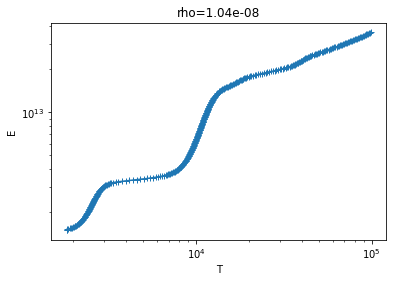

In [7]:
j=300
d=np.exp(eos.scale0.values[j])
lnE,lnP=eos.values(j,'ln(P)')
lnE,T=eos.values(j,'T')
P=np.exp(lnP)
lnT=np.log(T)
E=np.exp(lnE)
w=np.where(abs(lnT/np.log(10)-4)<1)[0]
pl.loglog(T[w],E[w],'-+')
pl.title('rho={:.2e}'.format(d))
pl.xlabel('T'); pl.ylabel('E');

## Differences in cross-derivatives

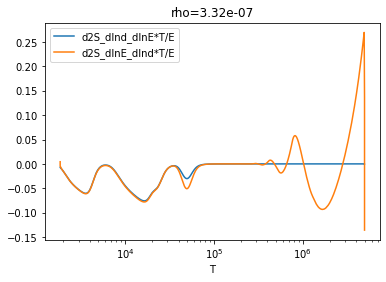

In [22]:
from dispatch.EOS import deriv,interp

def d2S_dlnE_dlnd(j0):
    def dS_dlnE(j):
        lnE,T=eos.values(j,'T')
        E=np.exp(lnE)
        return E/T,E,T
    j1=j0+1
    dS_dlnE_0,E0,T0=dS_dlnE(j0)        # dS_dlnE on E0 scale
    dS_dlnE_1,E1,T1=dS_dlnE(j1)        # dS_dlnE on E1 scale
    dS_dlnE_1=interp(E1,dS_dlnE_1,E0)  # dS_dlnE on E0 scale
    T1=interp(E1,T1,E0)                # T1 on E0 scale
    lnd_step=eos.scale0.step
    return (dS_dlnE_1-dS_dlnE_0)/lnd_step*(T0+T1)/(E0+E0),T1

def d2S_dlnd_dlnE(j0):
    """ \partial S^2 \over \partial\ln\rho \partial\ln E """
    def d2S(j):
        d=np.exp(eos.scale0.values[j])
        lnE,lnP=eos.values(j,'ln(P)')
        lnE,T=eos.values(j,'T')
        P=np.exp(lnP)
        lnT=np.log(T)
        E=np.exp(lnE)
        dS_dlnd=-P/(d*T)
        return deriv(lnE,dS_dlnd),E,T,lnE
    j1=j0+1
    d2S0,E0,T0,lnE0=d2S(j0)
    d2S1,E1,T1,lnE1=d2S(j1)
    d2S1=interp(E1,d2S1,E0)
    T1=interp(E1,T1,E0)
    return (d2S0+d2S1)/2*(T0+T1)/(E0+E0),T1
i=350
d2S_1,T1=d2S_dlnE_dlnd(i)
d2S_2,T2=d2S_dlnd_dlnE(i)
pl.semilogx(T1,d2S_1,label='d2S_dlnd_dlnE*T/E')
pl.semilogx(T1,d2S_2,label='d2S_dlnE_dlnd*T/E')
d=np.exp(eos.scale0.values[i])
pl.legend(); pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

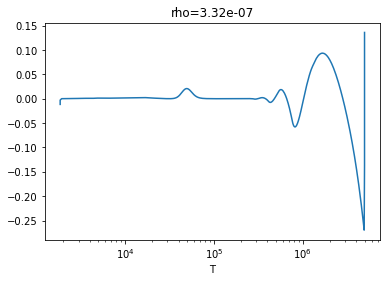

In [25]:
pl.semilogx(T1,d2S_1-d2S_2,label='difference');
pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

In the range below 500,000 K, the onconsistencies are relatively small, except for a feature associated with He-ionization:

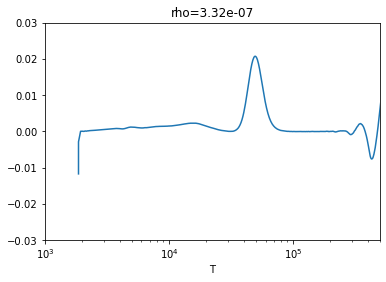

In [26]:
pl.ylim(-0.03,0.03); pl.xlim(1e3,5e5)
pl.semilogx(T1,d2S_1-d2S_2,label='difference');
pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

Multiple densities:

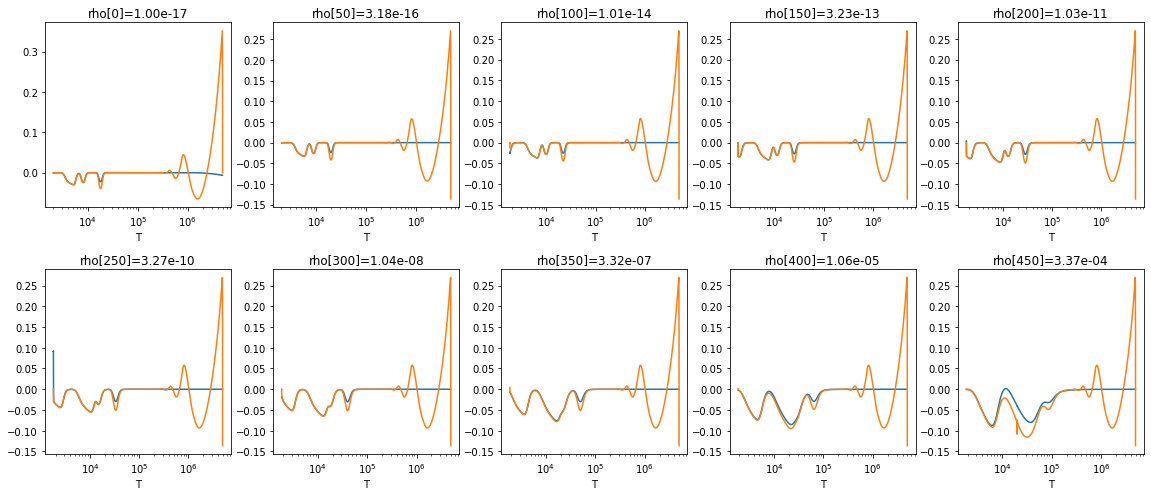

In [15]:
pl.figure(figsize=(16,7))
ip=1
Plot=pl.semilogx
for i in range(0,eos.scale0.n,50):
    d2S_1,T1=d2S_dlnE_dlnd(i)
    d2S_2,T2=d2S_dlnd_dlnE(i)
    pl.subplot(2,5,ip); ip+=1
    Plot(T1,d2S_1)
    Plot(T1,d2S_2)
    d=np.exp(eos.scale0.values[i])
    pl.title('rho[{}]={:.2e}'.format(i,d)); pl.xlabel('T');
pl.tight_layout()

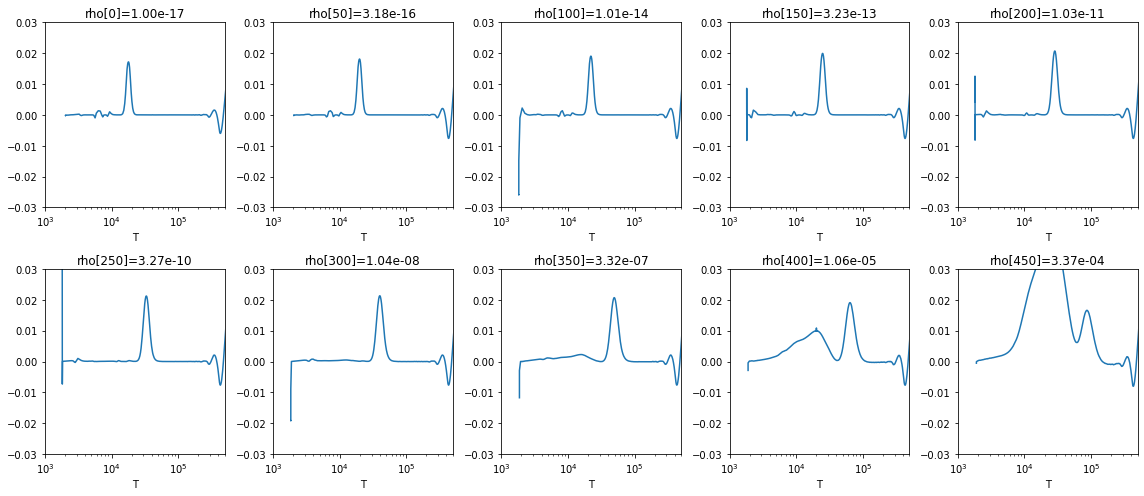

In [20]:
pl.figure(figsize=(16,7))
ip=1
Plot=pl.semilogx
for i in range(0,eos.scale0.n,50):
    d2S_1,T1=d2S_dlnE_dlnd(i)
    d2S_2,T2=d2S_dlnd_dlnE(i)
    pl.subplot(2,5,ip); ip+=1
    Plot(T1,d2S_1-d2S_2)
    d=np.exp(eos.scale0.values[i])
    pl.title('rho[{}]={:.2e}'.format(i,d)); pl.xlabel('T');
    pl.ylim(-0.03,0.03); pl.xlim(1e3,5e5)
pl.tight_layout()